# How to interpret Feature behaviors using SHAP

### <i> Bar, Beeswarm 

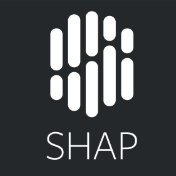

<i> 

<br>
<br>

Here is a basic example for how to benchmark your data using Shapley value plots together with metrics.

---

## Code

<i>

We start by making a simple `XGBoostRegressor` model and create some feature shap values.

In [1]:
import shap
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from xgboost import XGBRegressor

# Load into a single DataFrame
df = fetch_california_housing(as_frame=True).frame
df = df.rename(columns={"MedHouseVal": "target"}) 

# Split features / target from the DataFrame
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model
model = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, random_state=42)
model.fit(X_train, y_train)

# Prediction & Metrics (For Regression)
pred = model.predict(X_test)
print(f"RMSE: {mean_squared_error(y_test, pred) :.4f}")
print(f"R-squared: {r2_score(y_test, pred):.4f}")

# SHAP
explainer = shap.TreeExplainer(model)
sv = explainer(X_test)


RMSE: 0.2123
R-squared: 0.8380


<i>

And now we're going to use this to create some visuals and interpret them -- It'll eventually come to an insight that's quite interesting!

---

### <b> Question 1 that SHAP  bar/beeswarm answers: </b>

<i> 


<strong style='color:teal ; background-color:black;'>
"What features matter most to the model?"
</strong>


This question is most easily answered using a shapley bar plot.

</i>

<i> 

Interpreting `shap.plots.bar` is simple. <u> The higher the value, the more valuable the model believes this feature is.  </u>

<br>

What's really important to distinguish here:

<strong style='color:orange ; background-color:black;'> This bar plot indicates <u> what the model believes is important </u>, not what features are ACTUALLY increase accuracy for the model.</strong>

That's an easy mistake to make. Remember that Shapley values are always just interpreting the model's BEHAVIOR, not performance.


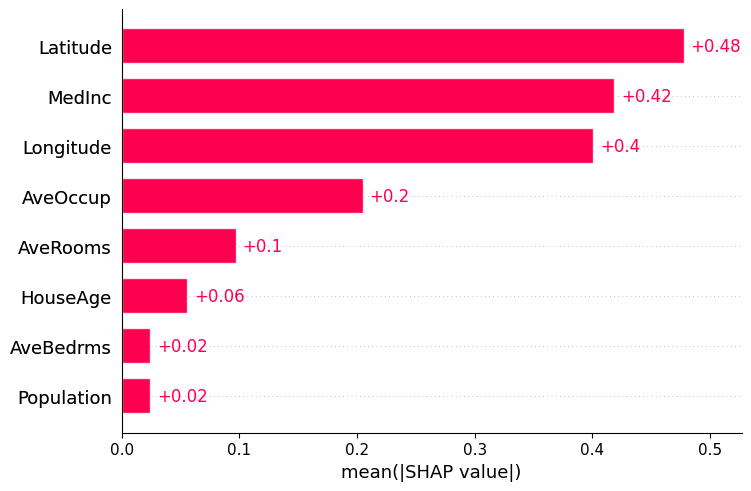

In [2]:
shap.plots.bar(sv)                                 

<i>

Here, we can see that `Latitude` and `MedInc` are the features that the MODEL believes is the most important.

---

### <b> Question 2 that beeswarm/bar answers: </b>

<br>
<br>

<i>

<strong style='color:#69d154 ; background-color:black;'>Why do certain features matter most? </strong>


The shap.plots.beeswarm can tell you why certain features are behaving a specific way in the model.

<u>Interpreting beeswarms are a bit more complicated, so just take everything one axis at a time </u> before we think about what the colors do:

<br></i>

<i>

<strong style='color:orange; background-color:black;'> Features (Y-axis)</strong>

These represent the features (variables) of your dataset.

<br>
<br>
<strong style='color:#7ff3f5 ; background-color:black;'> The SHAP value (X-axis)</strong>

The SHAP value (X-axis) determines how much each dot contributes to the prediction of your model. Veer to the left and it means this feature made the target variable go down. Veer to the right and it means this feature made the target variable go up.

<u><b>Note:</u></b> A Shapley value of zero means that the model didn't think that row was important at all!



<br>
<br>

<strong style='color:Violet ; background-color:black;'> Color meaning: </strong>

The color values, named`Feature Value`, reflect the dataset's <u>actual value</u>.

<u><b>For example:</u></b> If a row has a `MedInc` of `99999999999`, obviously it would be hot-red in the `MedInc` feature.

<br>
<br>

Now you should have all the pieces to look at beeswarm plots effectively.

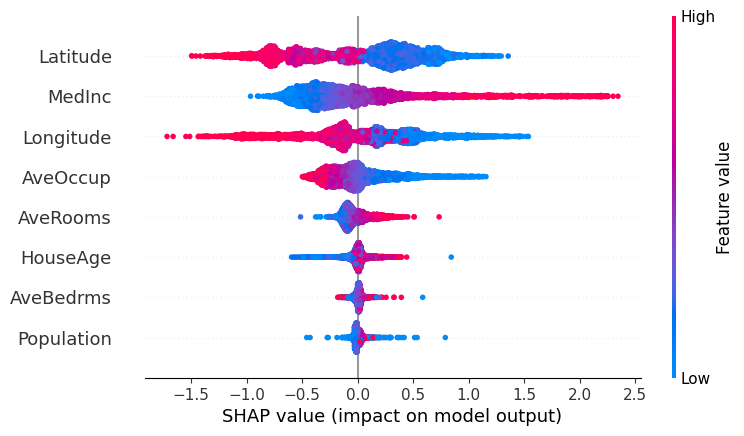

In [3]:
shap.plots.beeswarm(sv)

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>
<strong style='color:#f09269 ; background-color:black;'> How I would read this</strong>

I would start by understanding that <u> Shapley values and feature values not correlating with one another doesn't mean the feature is useless </u>. It just means non-linearity exists.

So how do you actually see what features a model thinks is important? 

You inspect how wide the variance is. Long variances on the X axis means shapley means this model thinks the feature is important.

More important variances are sorted from top to bottom. 

The top feature is the most important to the model. 

<br>

Now let's focus on an example:

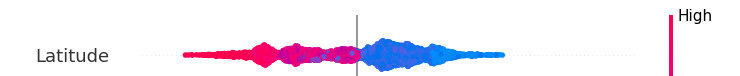

Notice how the color changes gradually along the x-axis. That is a linear correlation between the target and this feature. 

Also notice the long variance with some sensible Shapley distribution clusters. That's a good sign. (and it makes sense sense, because the further west you go, the more you enter the richer, bay area cities. With a couple of exceptions in NorCal)


<br>

Now, let's also notice the problematic features.

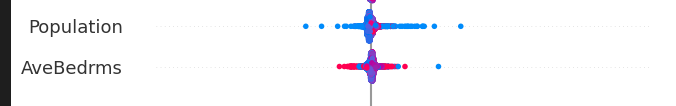

Here, we can see that `AveBedrooms` and `Population` are confusing this model a bit. The colors do not appear gradient (it is not linear). The x axis variance is low, too. This could be a sign that we're not extracting enough from this feature and the feature is less useful than the others.

This is indicated by the amount of colors scattered everywhere. There's no uniformness to it, no gradient, just scattered. 

<u>If the X-axis range is short for a feature --> the model is confused.</u>


<br>
<br>

<strong style='color:#f09269 ; background-color:black;'> Takeaways</strong>

* Does `AveBedrms`, `Population` really provide some meaning to this model?

* Can we fix it?



</div>




---

## Benchmarking our first change

<i>

### Removing `AveBedrms`


First we retrain the model without the `AveBedrms` 

Does the model still perform the same?


In [4]:
# Split features / target from the DataFrame
X = df.drop(columns=["target", "AveBedrms"])
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model
model = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, random_state=42)
model.fit(X_train, y_train)

# Prediction & Metrics
pred = model.predict(X_test)
print(f"RMSE: {mean_squared_error(y_test, pred) :.4f}")
print(f"R-squared: {r2_score(y_test, pred):.4f}")



RMSE: 0.2090
R-squared: 0.8405


<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

Good result --  We dropped the `AveBedrms` column and it performs roughly the same. Great, we could then simply drop the column to make the model more lean.

But this begs the question...

Can we improve `AveBedrms` instead?

That takes some experimentation. But the basic process is as seen above:

You make a change,      retrain,          check metrics+shap,            rinse-and-repeat. 



</div>

---


## Benchmarking our second change

### <i> Using Interaction Features 

We didn't get a lot out of the average amount of bedrooms column alone. 

So, let's create an interaction feature that may be more effective than the `AveBedrms` column. 

<br>

Let's make two new columns:

<br>

`BedroomRatio` = `AveBdrms` / `AveRooms`

`BedroomsPerPerson` = `AveBdrms`/ `AceOccup`

<br> <br>
  
These are likely more useful than bedrooms alone since wealthy people may have a lower `BedroomRatio` and `BedroomsPerPerson`. 

In [5]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [6]:
# Create two new interaction columns.
df["BedroomRatio"] = df["AveBedrms"] / df["AveRooms"]
df["BedroomsPerPerson"] = df["AveBedrms"] / df["AveOccup"]

In [7]:
import shap
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from xgboost import XGBRegressor

# Split features / target from the DataFrame
X = df.drop(columns=["target", "AveBedrms"])
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model
model = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, random_state=42)
model.fit(X_train, y_train)

# Prediction & Metrics
pred = model.predict(X_test)
print(f"RMSE: {mean_squared_error(y_test, pred) :.4f}")
print(f"R-squared: {r2_score(y_test, pred):.4f}")

# SHAP
explainer = shap.TreeExplainer(model)
sv = explainer(X_test)

RMSE: 0.2120
R-squared: 0.8382


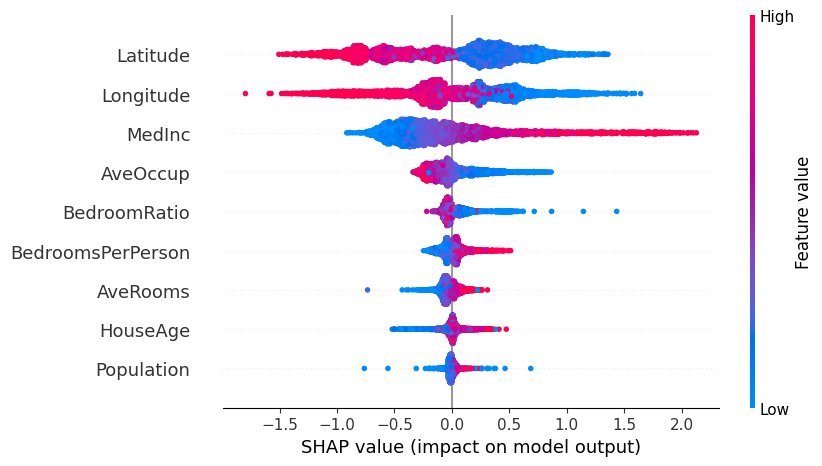

In [8]:
# Recreating the beeswarm plot
shap.plots.beeswarm(sv)



<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

While `Bedrms` alone was considered the least important by `XGBoost`, we turned it into a mid-ranking feature instead!

However, that came at the price of lower metrics.


|Change| Metrics|
|---|---|
|Raw data | 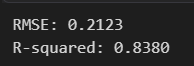 |
|Dropping `AveBedrms` | 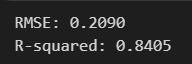|
| Creating `BedroomsRatio` `BedroomsPerPerson` instead | 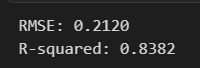  |

Also, take a look at the image below:

 

Notice how we also have some Shapley importance outliers to the right. The actual values are quite low and the importance is high. Could be outliers. Maybe `BedroomRatio` needs optimization.

I took this as a clue to perhaps try only having `BedroomsPerPerson` as a feature and retraining!

Feel free to keep experimenting yourself. No dataset is needed since it is loaded from `scikit-learn`. Run the notebook and enjoy. 

</div>

## Conclusion
<i> Hopefully this gave you some ideas about how to use both Shapley values and metrics to optimize your own dataset.

 Integrating SHAP + Metrics with your benchmarking is powerful! SHAP tells you the "why" and the metrics are our source-of-truth for performance:

##### <strong style="color:#31EB65; background-color:black;"> SHAP/Lime gives us glimpses of our model's behavior and logic. It can tell us where to continue optimizing data. </strong>



